# Lab 7 part 1
## Task 1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('../data/listings_clean.csv', parse_dates=date_columns)
print(listings.shape)

(4574, 73)


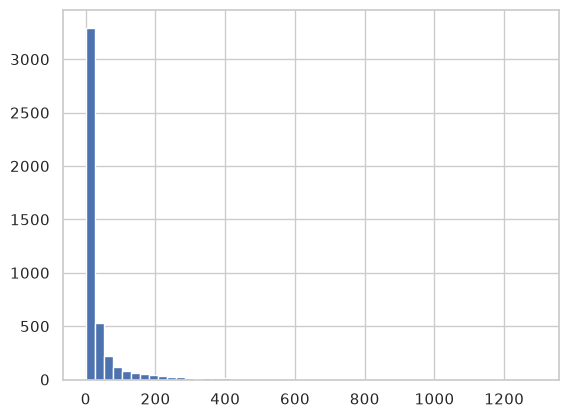

In [4]:
# With matplotlib

fig, ax = plt.subplots()
ax.hist(listings['number_of_reviews'].dropna(), bins=50)
plt.show()

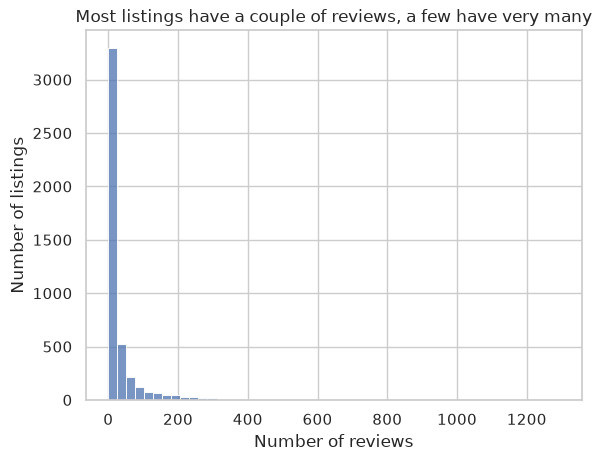

In [7]:
# With seaborn

fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.set_title('Most listings have a couple of reviews, a few have very many')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')

plt.show()

Matplotlib and Seaborn both allow for visualisasing data, but Seaborn has support for example titles and axis labels.

## Task 2

In [9]:
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()

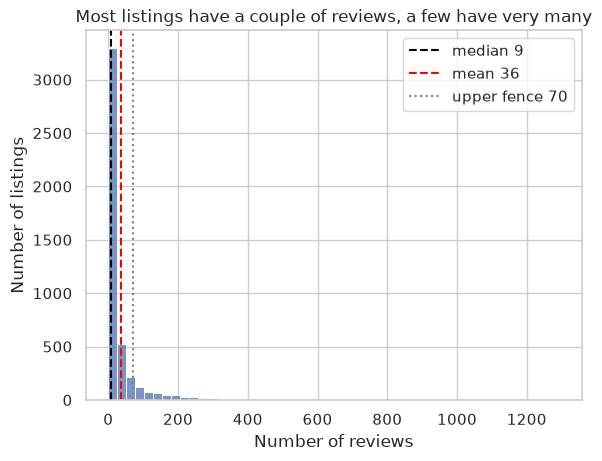

In [11]:
fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.set_title('Most listings have a couple of reviews, a few have very many')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')

ax.axvline(median, color='black', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='red', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='gray', linestyle=':', label=f'upper fence {upper:,.0f}')

ax.legend()

plt.show()

The line that is furthest to the right is the upper fence. The mean is further to the right than the median, due to a few very large values.

## Task 3

In [12]:
listings['reviews_outlier'] = listings['number_of_reviews'] > upper

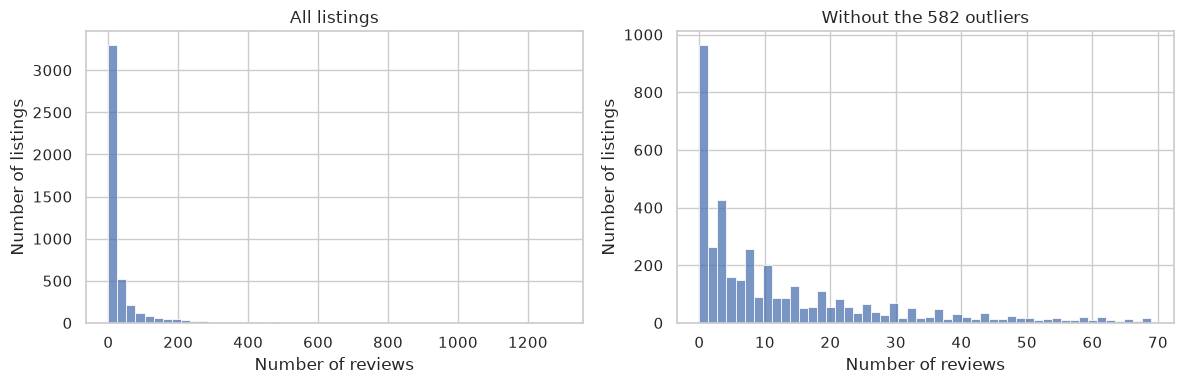

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])

outlier_count = listings['reviews_outlier'].sum()
axes[0].set_title('All listings')
axes[1].set_title(f'Without the {outlier_count} outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()

plt.show()

The plot without the outliers shows the distribution of the data with number of reviews between 0 and 70 with much more detail.

## Task 4

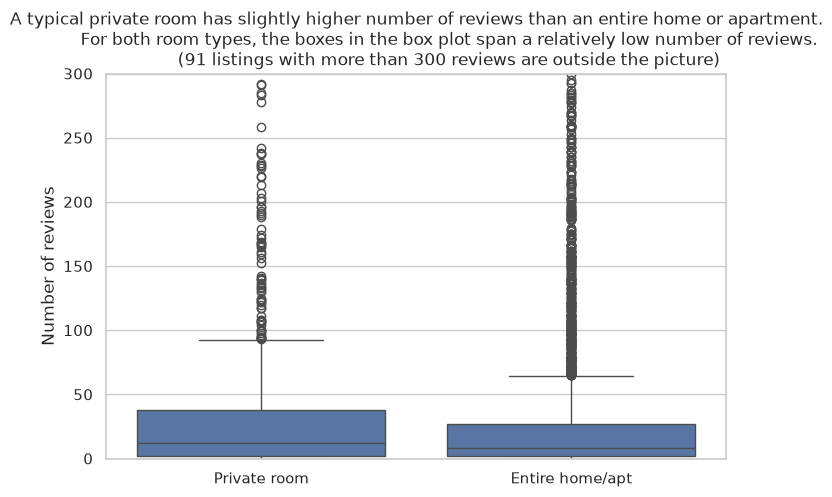

In [30]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=two_types, x='room_type', y='number_of_reviews', ax=ax)

y_limit = 300
count_above_limit = (listings["number_of_reviews"] > y_limit).sum()
ax.set_ylim(0, y_limit)
ax.set_title(f'A typical private room has slightly higher number of reviews than an entire home or apartment.\n\
             For both room types, the boxes in the box plot span a relatively low number of reviews.\n\
             ({count_above_limit} listings with more than {y_limit} reviews are outside the picture)')
ax.set_xlabel('')
ax.set_ylabel('Number of reviews')

plt.show()

## Task 5  
a)

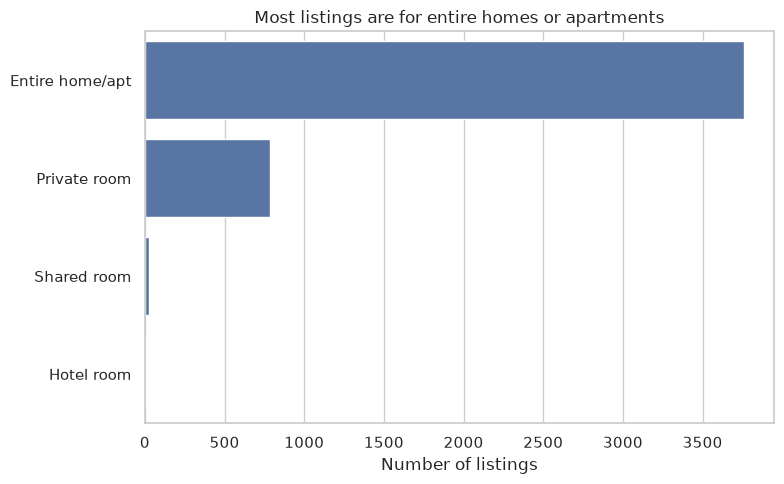

In [35]:
order = listings['room_type'].value_counts().index

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(data=listings, y='room_type', order=order, ax=ax)

ax.set_title('Most listings are for entire homes or apartments')
ax.set_xlabel('Number of listings')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

b)

In [43]:
by_area = (
    listings.groupby('neighbourhood_cleansed')['number_of_reviews']
    .agg(['median', 'count'])
    .sort_values('median', ascending=False)
    .reset_index()
)

by_area['label'] = by_area['neighbourhood_cleansed'] + ' (' + by_area['count'].astype(str) + ')'
by_area.head(3)

,neighbourhood_cleansed,median,count,label
0,Södermalms,17.0,1145,Södermalms (1145)
1,Kungsholmens,12.0,420,Kungsholmens (420)
2,Norrmalms,10.0,469,Norrmalms (469)


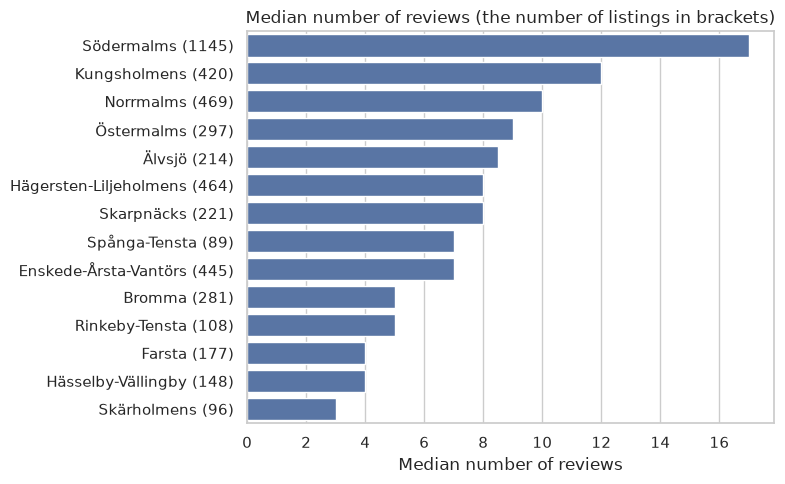

In [45]:
fif, ax = plt.subplots(figsize=(8, 5))

sns.barplot(data=by_area, x='median', y='label', ax=ax)

ax.set_title('Median number of reviews (the number of listings in brackets)')
ax.set_xlabel('Median number of reviews')
ax.set_ylabel('')

plt.tight_layout()
plt.show()

The neighbourhood with the highest median is Södermalms.  
The neighbourhood with the most listings is also Södermalms.


# Task 6


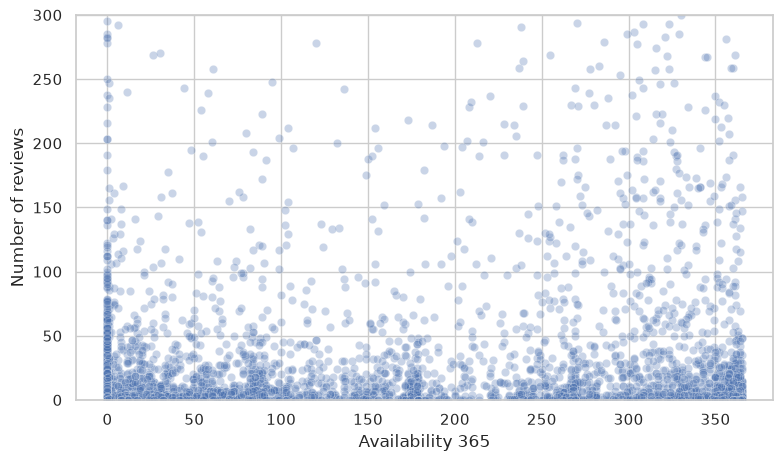

In [51]:

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=listings, x='availability_365', y='number_of_reviews', alpha=0.3, ax=ax)
ax.set_ylim(0, 300)

ax.set_title('')
ax.set_xlabel('Availability 365')
ax.set_ylabel('Number of reviews')

plt.show()

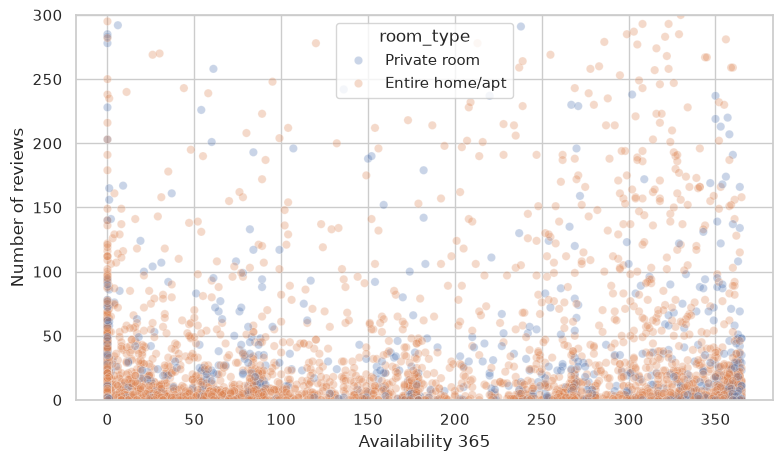

In [62]:
two_most_common_types = listings["room_type"].value_counts(sort=True).keys()[:2]
most_common_types_data = listings[listings["room_type"].isin(two_most_common_types)]

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=most_common_types_data, x='availability_365', y='number_of_reviews', alpha=0.3, hue='room_type', ax=ax)
ax.set_ylim(0, 300)

ax.set_title('')
ax.set_xlabel('Availability 365')
ax.set_ylabel('Number of reviews')

plt.show()

There is no clear pattern to be observed, which matches the weak correlation of 0.18.

## Task 7
a)

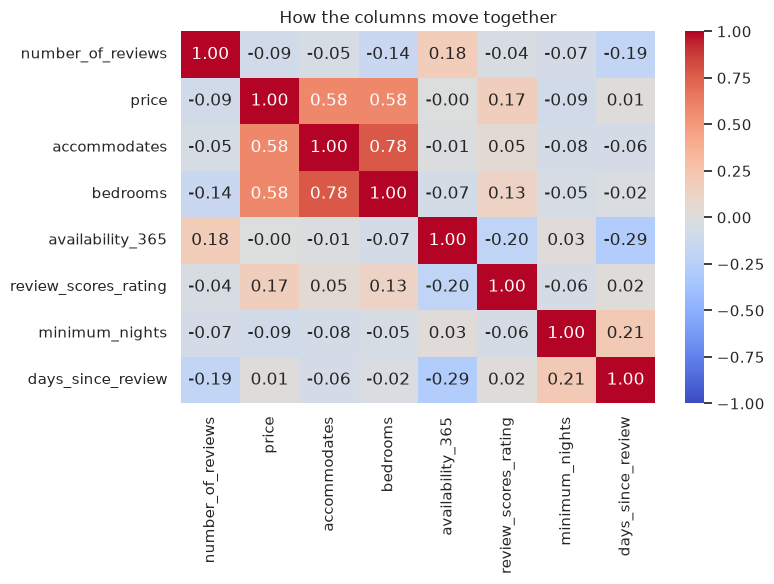

In [67]:
columns = ['number_of_reviews', 'price', 'accommodates', 'bedrooms', 'availability_365', 
           'review_scores_rating', 'minimum_nights', 'days_since_review']
corr = listings[columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('How the columns move together')

plt.tight_layout()
plt.show()

b)

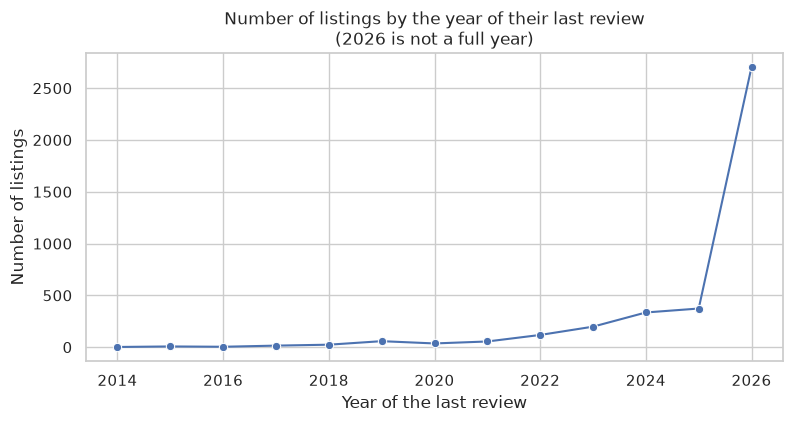

In [68]:
listings['last_review']
per_year = listings['last_review'].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9,4))
sns.lineplot(x=per_year.index, y=per_year.values, marker='o', ax= ax)

ax.set_title('Number of listings by the year of their last review\n(2026 is not a full year)')
ax.set_xlabel('Year of the last review')
ax.set_ylabel('Number of listings')

plt.show()

The last year 2026 is shows a significant increase in the number of listings. Every active listing is likely to have recieved a review this year, and thus the latest year is the most common value.  
It also differs from the other years because it is does not yet have data for a complete year (the data only goes as far as September 2026).